# Fase 4 Interpretabilidad XGBoost

Modelo exacto de Fase 3, 24 rondas efectivas, solo Validation. SHAP explica contribuciones del modelo; no causalidad.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
r=json.loads((ROOT/'artifacts/interpretability_summary.json').read_text())
importance=pd.read_csv(ROOT/'artifacts/shap_global_importance.csv')
display(r['sample'])
display(r['validation_metrics'])

{'rows': 2868, 'frauds': 868, 'nonfrauds': 2000, 'fraud_fraction': 0.30264993026499304, 'seed': 42, 'method': 'All Validation frauds plus uniform 2,000 nonfrauds without replacement', 'selected_indices_sha256': '37028ade879a16c21bf5ccb48af4069a66f2db4f0ac43233b71832b7892582f2', 'prevalence_weighted_importance': 'Fraud prevalence * fraud mean absolute SHAP + nonfraud prevalence * random nonfraud mean absolute SHAP; estimated, not full population SHAP'}

{'pr_auc': 0.9999185900788442, 'roc_auc': 0.9999999719684873, 'precision_05': 1.0, 'recall_05': 0.9988479262672811, 'f1_05': 0.9994236311239193, 'f2_05': 0.9990781286010602, 'tp': 867, 'fp': 0, 'tn': 1397374, 'fn': 1, 'k_0.1pct': 1399, 'precision_top_0.1pct': 0.6204431736954967, 'recall_top_0.1pct': 1.0, 'k_0.5pct': 6992, 'precision_top_0.5pct': 0.12414187643020595, 'recall_top_0.5pct': 1.0, 'k_1pct': 13983, 'precision_top_1pct': 0.06207537724379604, 'recall_top_1pct': 1.0}

## Global y comparación nativa

Importancia de muestra enriquecida y estimación ponderada por prevalencia se presentan por separado. Unidades log-odds. No se atribuye causalidad.

,feature,mean_abs_shap,mean_abs_shap_fraud,mean_abs_shap_nonfraud,mean_abs_shap_prevalence_weighted,mean_signed_shap_fraud,mean_signed_shap_nonfraud,native_gain,native_split_count,shap_sample_rank,shap_population_estimate_rank,native_gain_rank
0,orig_balance_emptied,2.177891,6.625342,0.247694,0.251653,6.618984,-0.247694,44566.402344,18.0,1,1,1
1,amount_to_oldbalanceOrg,0.387300,1.187255,0.040120,0.040833,1.186534,-0.029473,3890.905762,40.0,2,5,3
2,amount,0.162184,0.423262,0.048875,0.049108,0.421858,-0.018133,462.143860,58.0,3,3,8
3,oldbalanceDest,0.116012,0.251112,0.057378,0.057498,0.240388,0.024583,793.911926,40.0,4,2,6
4,oldbalanceOrg,0.113520,0.277040,0.042554,0.042699,0.266731,-0.023301,679.849670,43.0,5,4,7
5,type_TRANSFER,0.077945,0.212207,0.019675,0.019795,0.203464,-0.007291,903.499939,8.0,6,7,4
6,type_CASH_OUT,0.058412,0.101460,0.039729,0.039768,-0.017859,-0.020846,216.788086,31.0,7,6,9
7,step,0.007054,0.008164,0.006572,0.006573,-0.007374,-0.006451,13.220498,47.0,8,8,12
8,dest_is_merchant,0.004891,0.010293,0.002547,0.002552,0.010293,-0.002198,4036.976562,1.0,9,11,2
9,type_CASH_IN,0.004273,0.007900,0.002698,0.002701,0.007900,-0.002301,809.769836,3.0,10,10,5


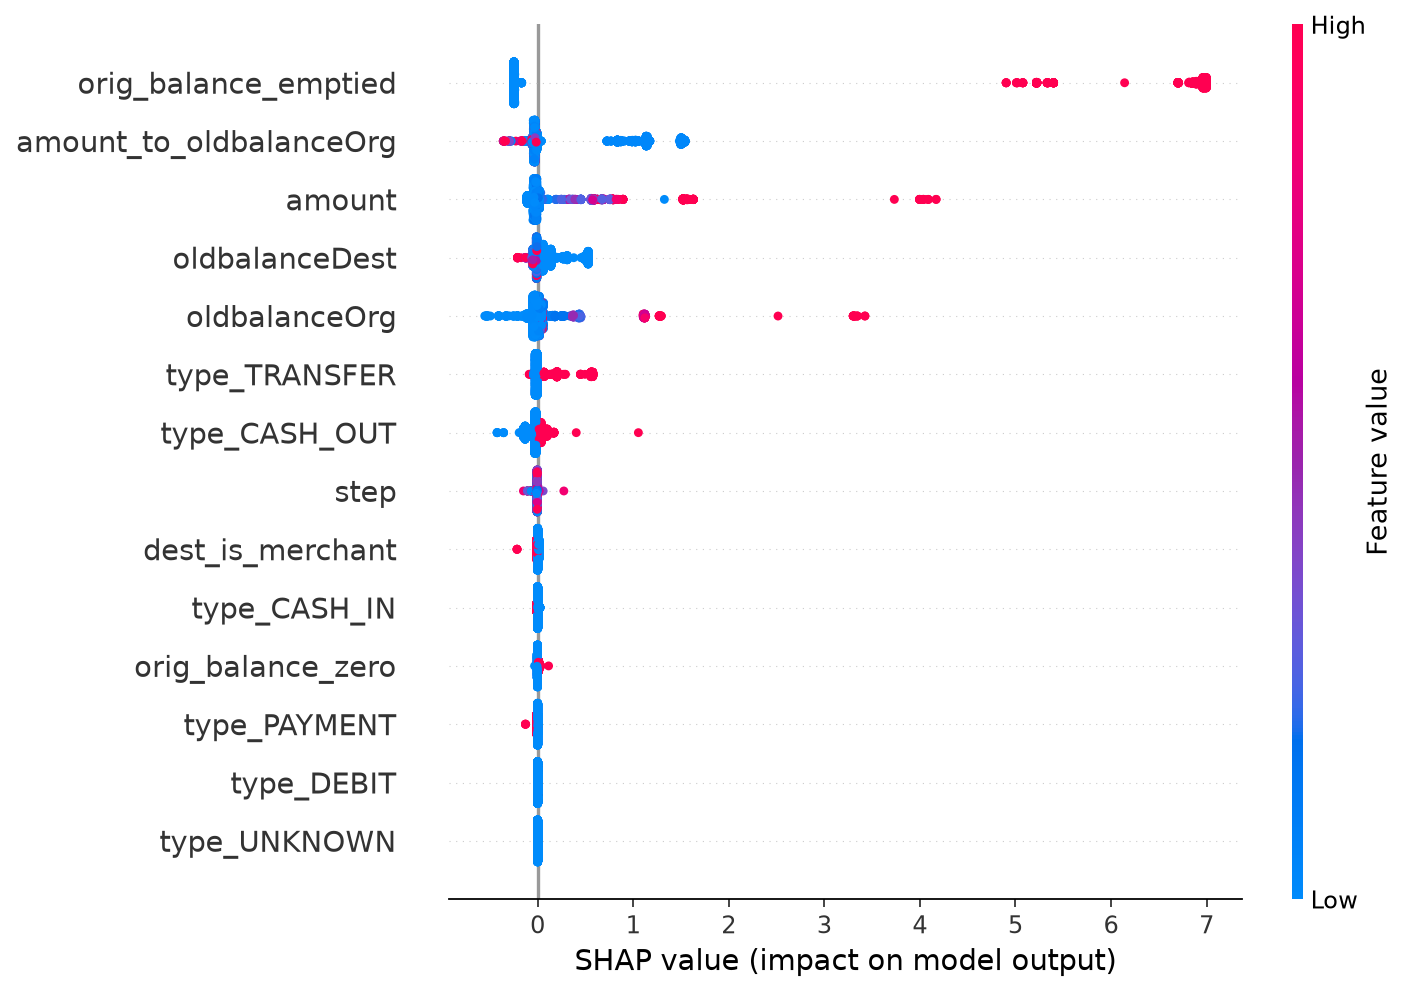

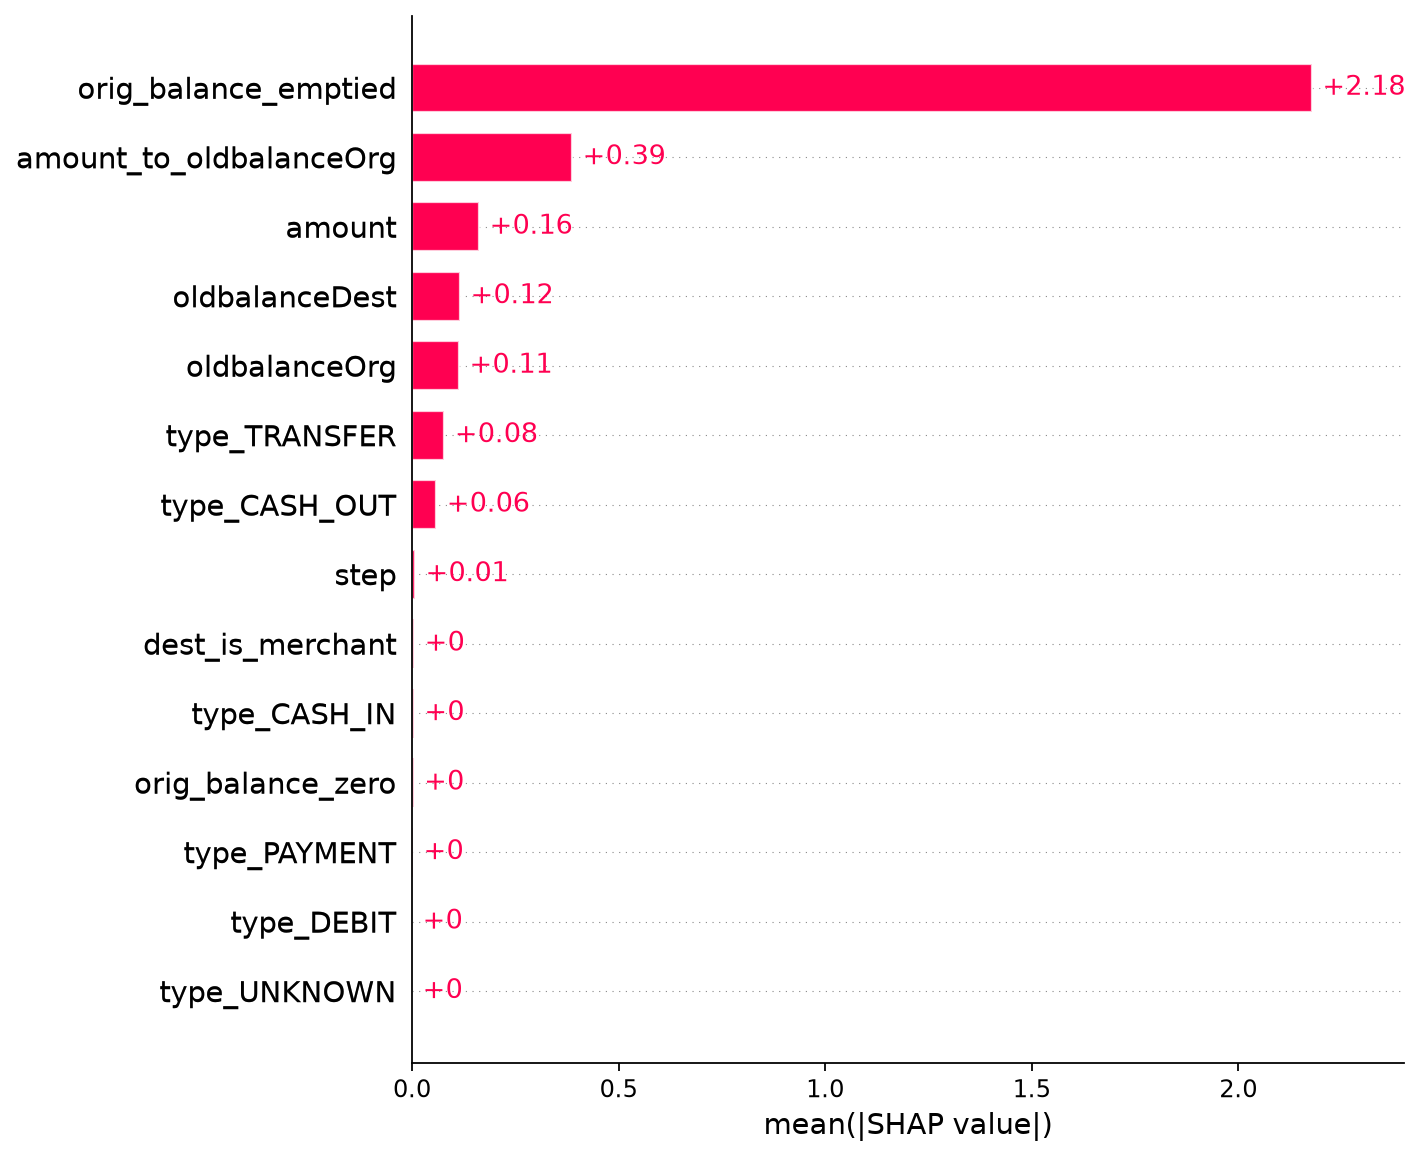

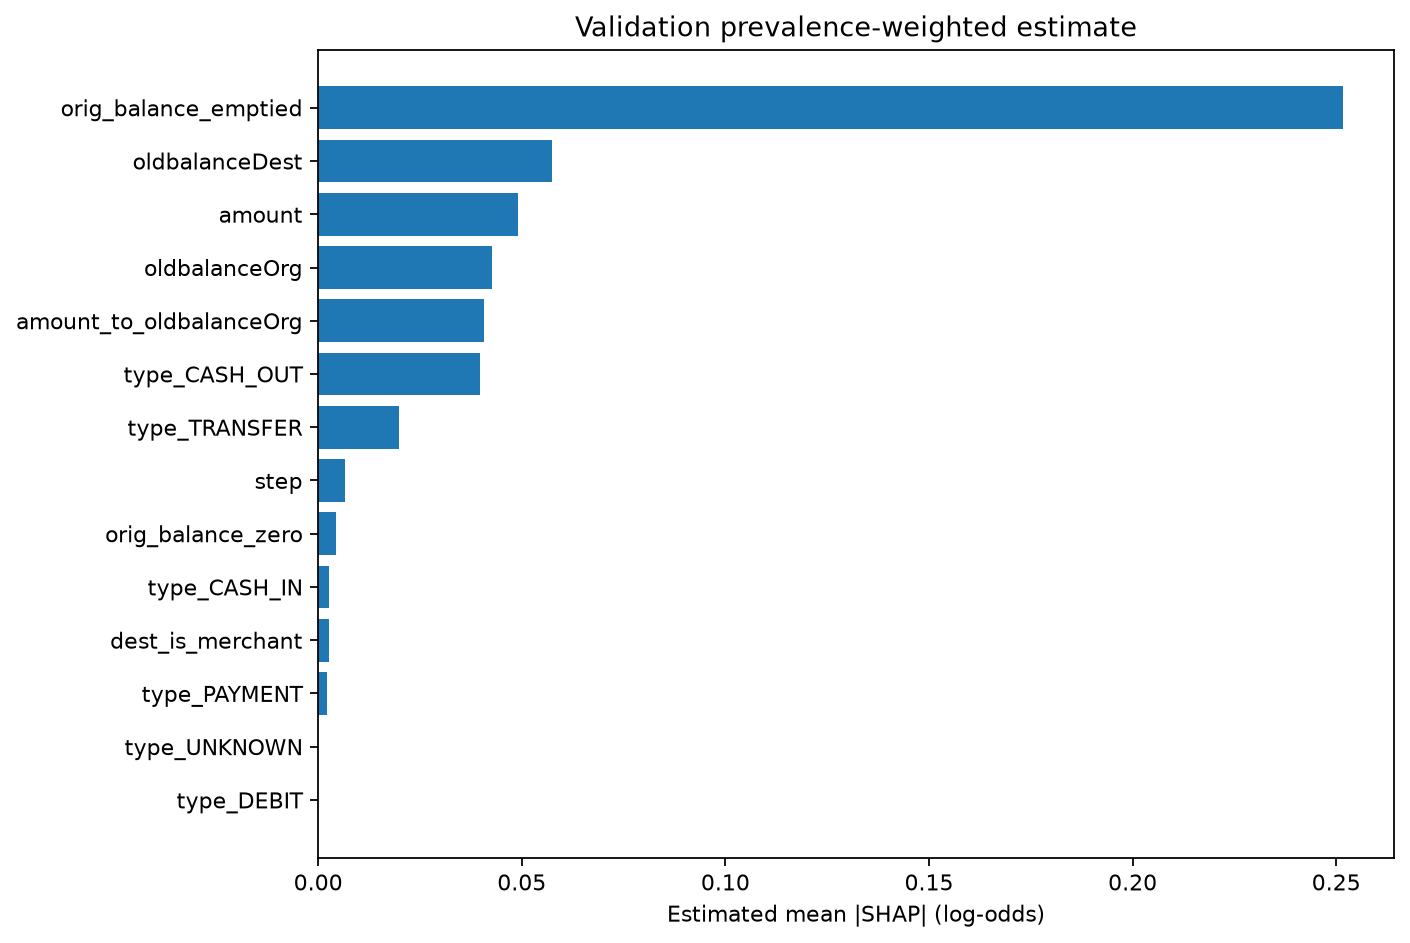

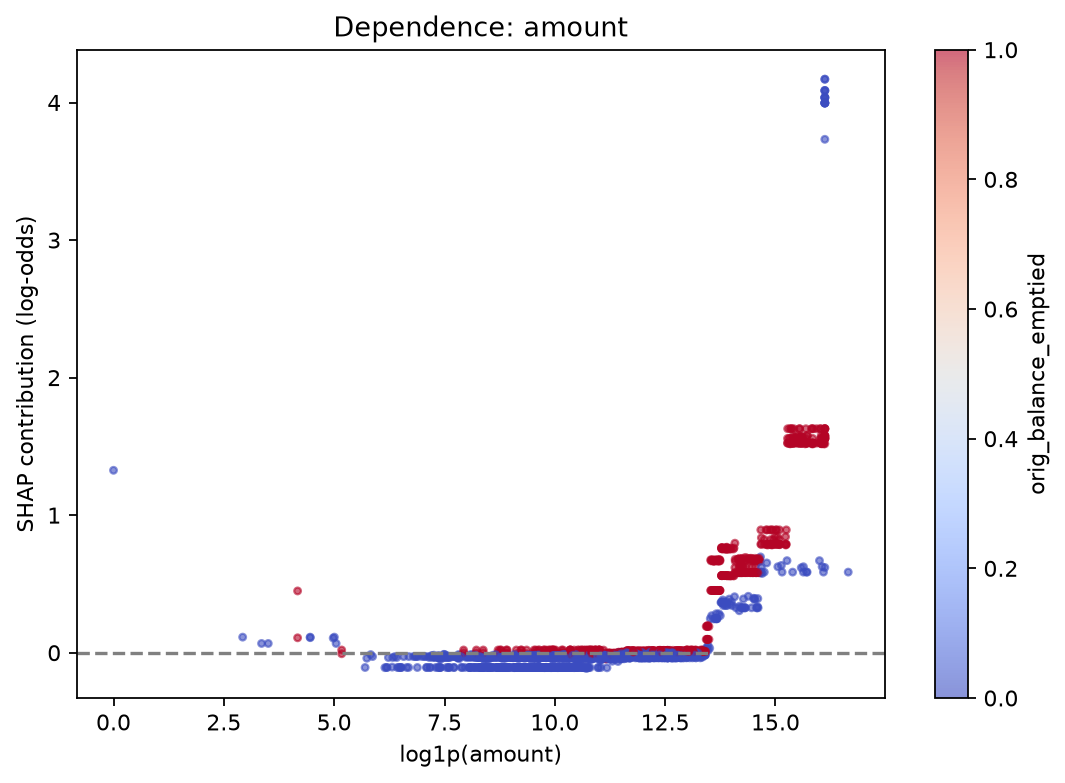

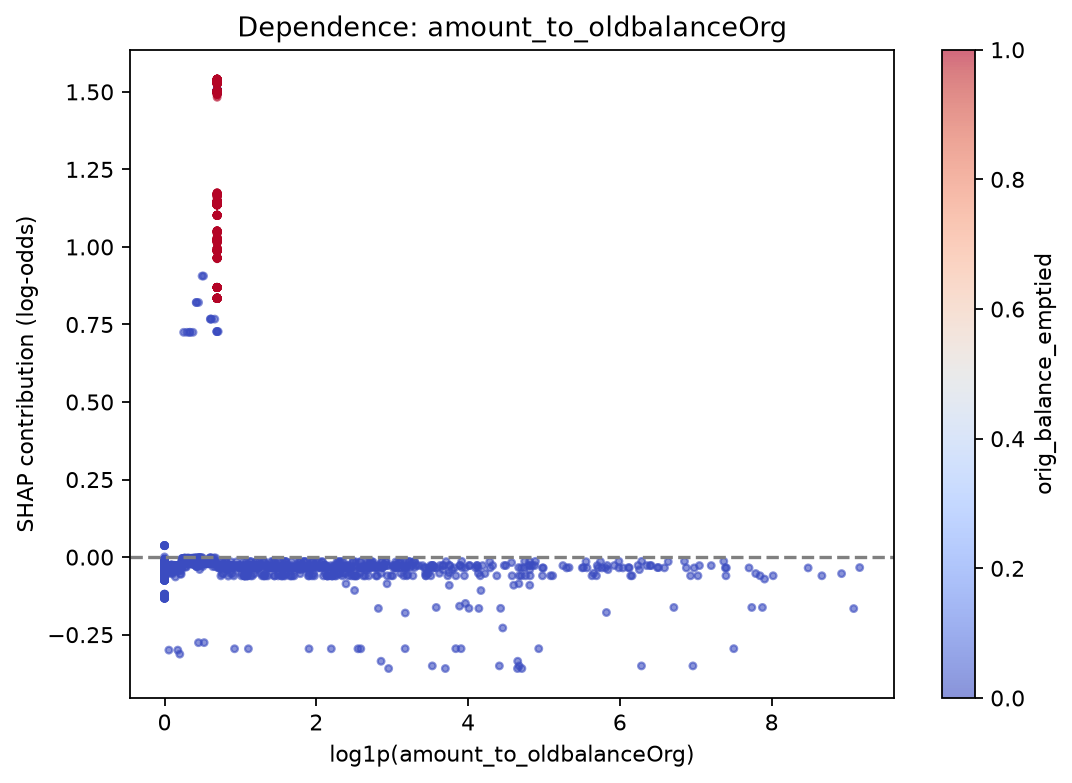

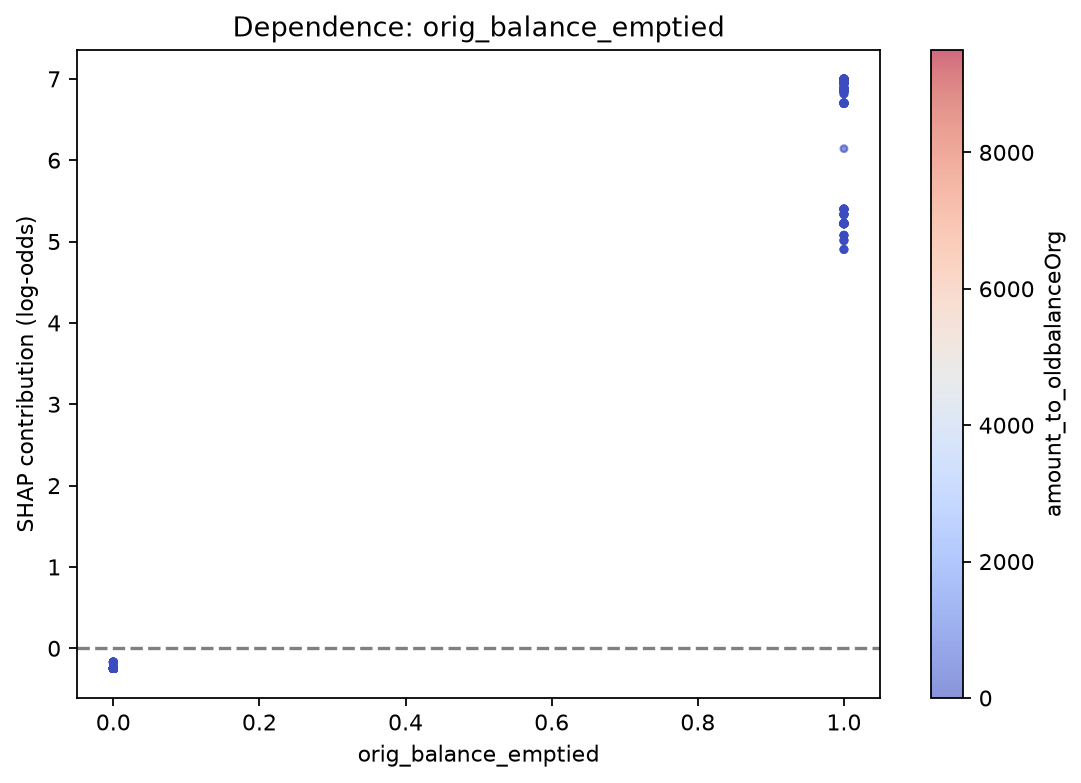

In [2]:
display(importance)
for name in ['shap_beeswarm.png','shap_global_bar.png','shap_prevalence_weighted_bar.png']:
    display(Image(filename=str(ROOT/'reports/figures/interpretability'/name)))
for path in sorted((ROOT/'reports/figures/interpretability').glob('dependence_*.png')):
    display(Image(filename=str(path)))

## Vaciado y fraudes fuera de regla

La feature dominante no explica todos los fraudes. Revisar señales de monto/saldo en los 16 casos fuera de regla.

In [3]:
display(r['emptied'])
display(r['outside_rule'])
display(pd.read_csv(ROOT/'artifacts/non_rule_fraud_explanations.csv'))

{'sample_rank': 1, 'mean_abs_shap': 2.1778907775878906, 'states': {'0': {'rows': 2016, 'mean_shap': -0.2470957189798355, 'median_shap': -0.2479453682899475, 'mean_score': 0.010702332481741905}, '1': {'rows': 852, 'mean_shap': 6.746533393859863, 'median_shap': 6.960999011993408, 'mean_score': 0.9744666814804077}}}

{'rows': 16, 'fraud_fraction': 0.018433179723502304, 'detected': 15, 'detection_rate': 0.9375, 'score_min': 0.05734940618276596, 'score_max': 0.9744994044303894, 'top_features': [{'feature': 'amount', 'mean_abs_shap': 3.8615705966949463}, {'feature': 'oldbalanceOrg', 'mean_abs_shap': 3.080129623413086}, {'feature': 'amount_to_oldbalanceOrg', 'mean_abs_shap': 0.7051246762275696}, {'feature': 'oldbalanceDest', 'mean_abs_shap': 0.4827547073364258}, {'feature': 'orig_balance_emptied', 'mean_abs_shap': 0.17245061695575714}], 'correctly_detected_score_summary': [0.967110276222229, 0.9625838398933411, 0.9625838398933411, 0.967110276222229, 0.9625838398933411, 0.9589652419090271, 0.9625838398933411, 0.7163143157958984, 0.9589652419090271, 0.9589652419090271, 0.9744994044303894, 0.9589652419090271, 0.967110276222229, 0.9589652419090271, 0.9744994044303894], 'rows_artifact': 'artifacts/non_rule_fraud_explanations.csv'}

,validation_row_index,score,prediction_05,step,amount,oldbalanceOrg,oldbalanceDest,amount_to_oldbalanceOrg,orig_balance_zero,orig_balance_emptied,dest_is_merchant,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,type_UNKNOWN,top_abs_shap_features,positive_contributors
0,644394,0.967110,1,354.0,10000000.0,19299230.0,0.0,0.518155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,"[{""feature"": ""amount"", ""shap_log_odds"": 4.086879253387451}, {""feature"": ""oldbalanceOrg"", ""shap_log_odds"": 3.34552001953125}, {""feature"": ""amount_to_oldbalanceOrg"", ""shap_log_odds"": 0.8209601640701294}, {""feature"": ""oldbalanceDest"", ""shap_log_odds"": 0.5049921274185181}, {""feature"": ""orig_balance_emptied"", ""shap_log_odds"": -0.16929514706134796}]","[{""feature"": ""amount"", ""value"": 10000000.0, ""shap_log_odds"": 4.086879253387451}, {""feature"": ""oldbalanceOrg"", ""value"": 19299230.0, ""shap_log_odds"": 3.34552001953125}, {""feature"": ""amount_to_oldbalanceOrg"", ""value"": 0.5181553959846497, ""shap_log_odds"": 0.8209601640701294}, {""feature"": ""oldbalanceDest"", ""value"": 0.0, ""shap_log_odds"": 0.5049921274185181}, {""feature"": ""type_TRANSFER"", ""value"": 1.0, ""shap_log_odds"": 0.15785111486911774}]"
1,770843,0.962584,1,357.0,10000000.0,10653152.0,0.0,0.938689,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,"[{""feature"": ""amount"", ""shap_log_odds"": 4.036200523376465}, {""feature"": ""oldbalanceOrg"", ""shap_log_odds"": 3.317124843597412}, {""feature"": ""amount_to_oldbalanceOrg"", ""shap_log_odds"": 0.7673606276512146}, {""feature"": ""oldbalanceDest"", ""shap_log_odds"": 0.5037287473678589}, {""feature"": ""orig_balance_emptied"", ""shap_log_odds"": -0.16964638233184814}]","[{""feature"": ""amount"", ""value"": 10000000.0, ""shap_log_odds"": 4.036200523376465}, {""feature"": ""oldbalanceOrg"", ""value"": 10653152.0, ""shap_log_odds"": 3.317124843597412}, {""feature"": ""amount_to_oldbalanceOrg"", ""value"": 0.9386893510818481, ""shap_log_odds"": 0.7673606276512146}, {""feature"": ""oldbalanceDest"", ""value"": 0.0, ""shap_log_odds"": 0.5037287473678589}, {""feature"": ""type_TRANSFER"", ""value"": 1.0, ""shap_log_odds"": 0.15785111486911774}]"
2,790223,0.962584,1,359.0,10000000.0,12056779.0,0.0,0.829409,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,"[{""feature"": ""amount"", ""shap_log_odds"": 4.036200523376465}, {""feature"": ""oldbalanceOrg"", ""shap_log_odds"": 3.317124843597412}, {""feature"": ""amount_to_oldbalanceOrg"", ""shap_log_odds"": 0.7673606276512146}, {""feature"": ""oldbalanceDest"", ""shap_log_odds"": 0.5037287473678589}, {""feature"": ""orig_balance_emptied"", ""shap_log_odds"": -0.16964638233184814}]","[{""feature"": ""amount"", ""value"": 10000000.0, ""shap_log_odds"": 4.036200523376465}, {""feature"": ""oldbalanceOrg"", ""value"": 12056779.0, ""shap_log_odds"": 3.317124843597412}, {""feature"": ""amount_to_oldbalanceOrg"", ""value"": 0.8294088840484619, ""shap_log_odds"": 0.7673606276512146}, {""feature"": ""oldbalanceDest"", ""value"": 0.0, ""shap_log_odds"": 0.5037287473678589}, {""feature"": ""type_TRANSFER"", ""value"": 1.0, ""shap_log_odds"": 0.15785111486911774}]"
3,799030,0.967110,1,362.0,10000000.0,17677120.0,0.0,0.565703,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,"[{""feature"": ""amount"", ""shap_log_odds"": 4.086879253387451}, {""feature"": ""oldbalanceOrg"", ""shap_log_odds"": 3.34552001953125}, {""feature"": ""amount_to_oldbalanceOrg"", ""shap_log_odds"": 0.8209601640701294}, {""feature"": ""oldbalanceDest"", ""shap_log_odds"": 0.5049921274185181}, {""feature"": ""orig_balance_emptied"", ""shap_log_odds"": -0.16929514706134796}]","[{""feature"": ""amount"", ""value"": 10000000.0, ""shap_log_odds"": 4.086879253387451}, {""feature"": ""oldbalanceOrg"", ""value"": 17677120.0, ""shap_log_odds"": 3.34552001953125}, {""feature"": ""amount_to_oldbalanceOrg"", ""value"": 0.5657029747962952, ""shap_log_odds"": 0.8209601640701294}, {""feature"": ""oldbalanceDest"", ""value"": 0.0, ""shap_log_odds"": 0.50499

## Casos locales TP TN FN FP y frontera

Threshold 0.5 = reference threshold, not final production threshold. No existe FP; el caso más próximo a 0.5 está a distancia 0.216314 y no se presenta como auténticamente cercano.

{'A_high_score_TP': {'exists': True, 'validation_row_index': 30299, 'step': 322, 'label': 1, 'score': 0.9790554642677307, 'prediction_05': 1, 'distance_to_reference_threshold': 0.4790554642677307, 'base_log_odds': -5.281437873840332, 'features': {'step': 322.0, 'amount': 2533650.0, 'oldbalanceOrg': 2533650.0, 'oldbalanceDest': 0.0, 'amount_to_oldbalanceOrg': 1.0, 'orig_balance_zero': 0.0, 'orig_balance_emptied': 1.0, 'dest_is_merchant': 0.0, 'type_CASH_IN': 0.0, 'type_CASH_OUT': 0.0, 'type_DEBIT': 0.0, 'type_PAYMENT': 0.0, 'type_TRANSFER': 1.0, 'type_UNKNOWN': 0.0}, 'positive_contributors': [{'feature': 'orig_balance_emptied', 'value': 1.0, 'shap_log_odds': 6.699925422668457}, {'feature': 'amount_to_oldbalanceOrg', 'value': 1.0, 'shap_log_odds': 0.8346683382987976}, {'feature': 'amount', 'value': 2533650.0, 'shap_log_odds': 0.7885299324989319}, {'feature': 'oldbalanceOrg', 'value': 2533650.0, 'shap_log_odds': 0.37611013650894165}, {'feature': 'oldbalanceDest', 'value': 0.0, 'shap_log_o

,case,validation_row_index,true_label,score,prediction_05,base_log_odds,feature,feature_value,shap_log_odds,absolute_rank
0,A_high_score_TP,30299,1,0.979055,1,-5.281438,orig_balance_emptied,1.000000e+00,6.699925,1
1,A_high_score_TP,30299,1,0.979055,1,-5.281438,amount_to_oldbalanceOrg,1.000000e+00,0.834668,2
2,A_high_score_TP,30299,1,0.979055,1,-5.281438,amount,2.533650e+06,0.788530,3
3,A_high_score_TP,30299,1,0.979055,1,-5.281438,oldbalanceOrg,2.533650e+06,0.376110,4
4,A_high_score_TP,30299,1,0.979055,1,-5.281438,oldbalanceDest,0.000000e+00,0.308940,5
5,A_high_score_TP,30299,1,0.979055,1,-5.281438,type_TRANSFER,1.000000e+00,0.202108,6
6,A_high_score_TP,30299,1,0.979055,1,-5.281438,type_CASH_OUT,0.000000e+00,-0.079543,7
7,A_high_score_TP,30299,1,0.979055,1,-5.281438,step,3.220000e+02,-0.022306,8
8,A_high_score_TP,30299,1,0.979055,1,-5.281438,dest_is_merchant,0.000000e+00,0.010895,9
9,A_high_score_TP,30299,1,0.979055,1,-5.281438,type_CASH_IN,0.000000e+00,0.006812,10


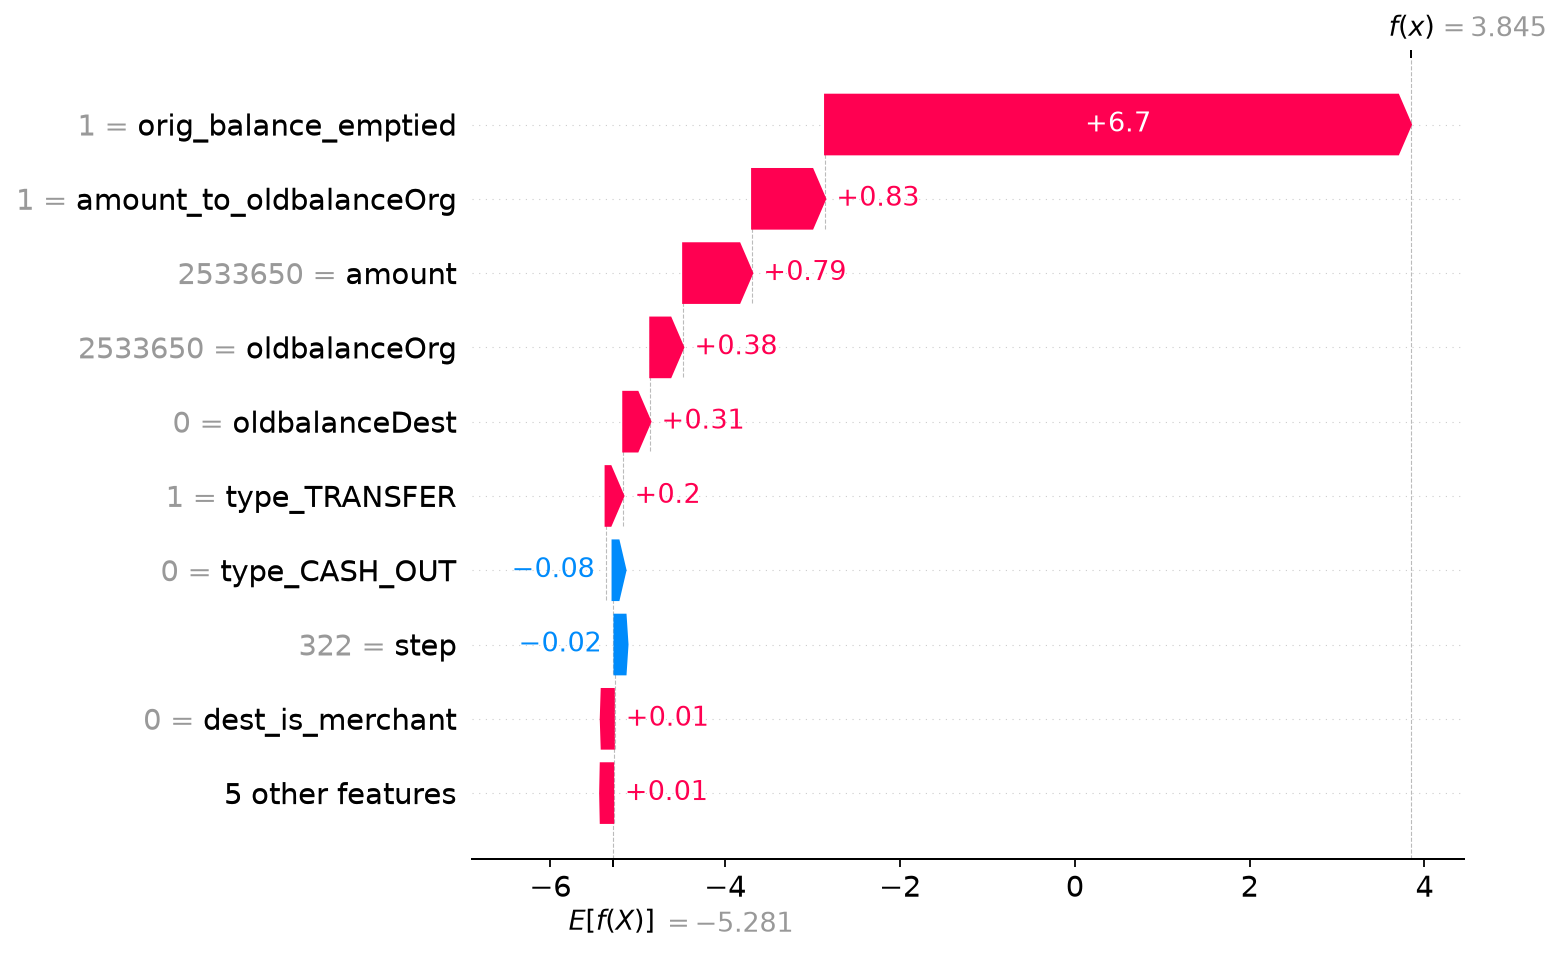

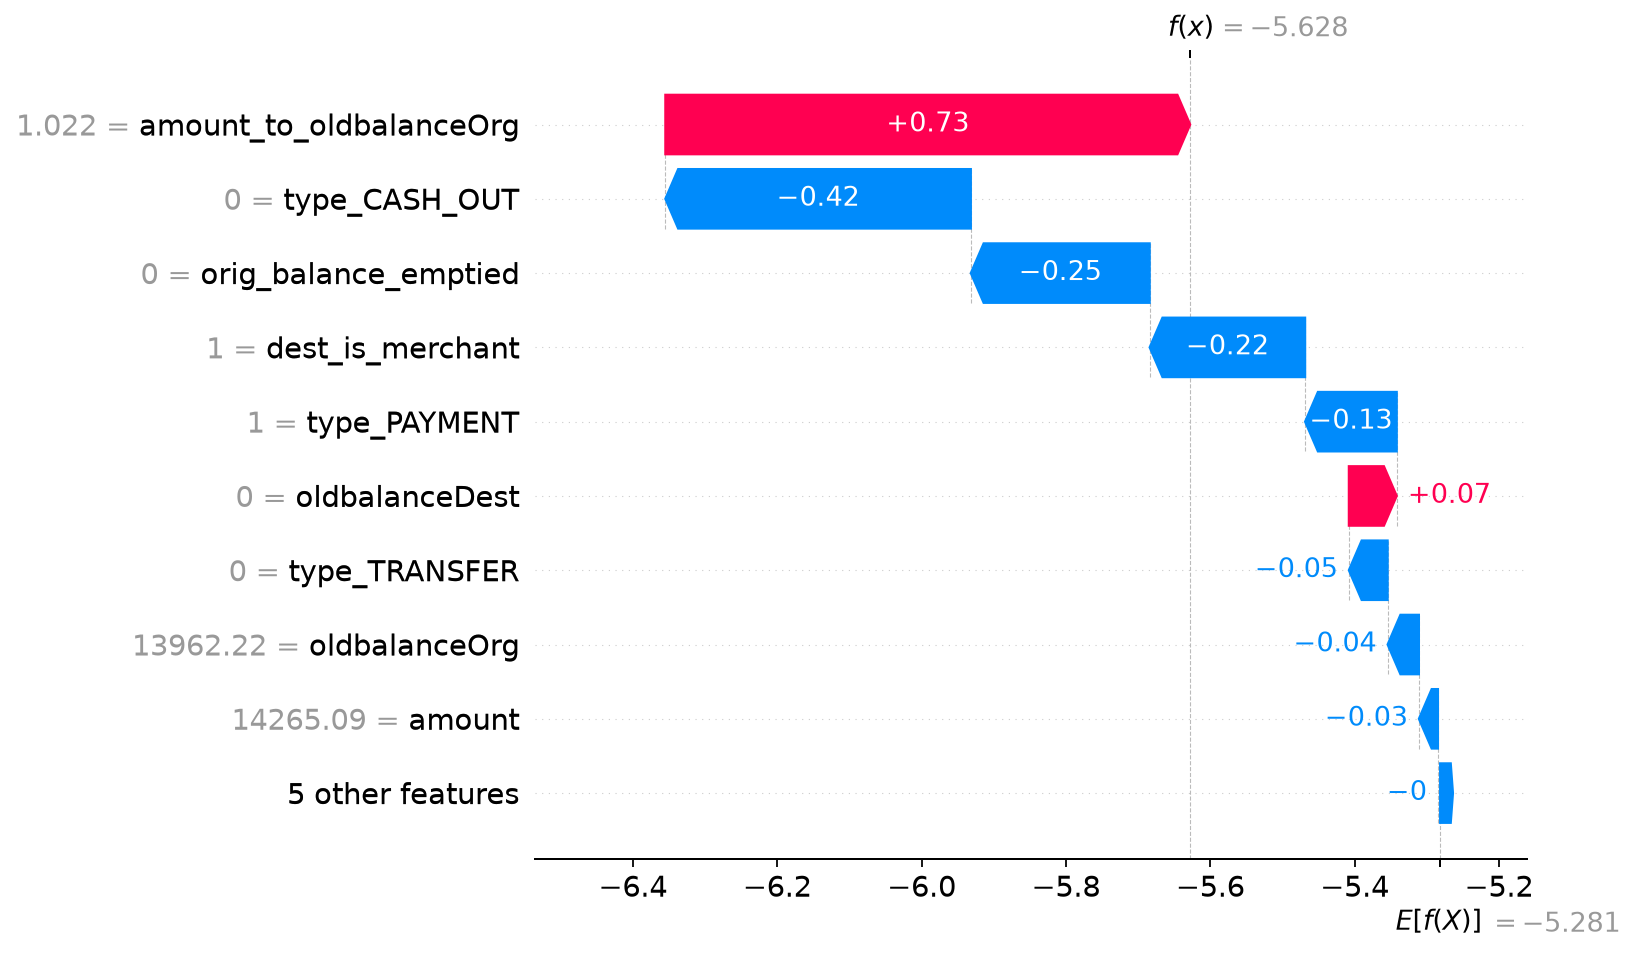

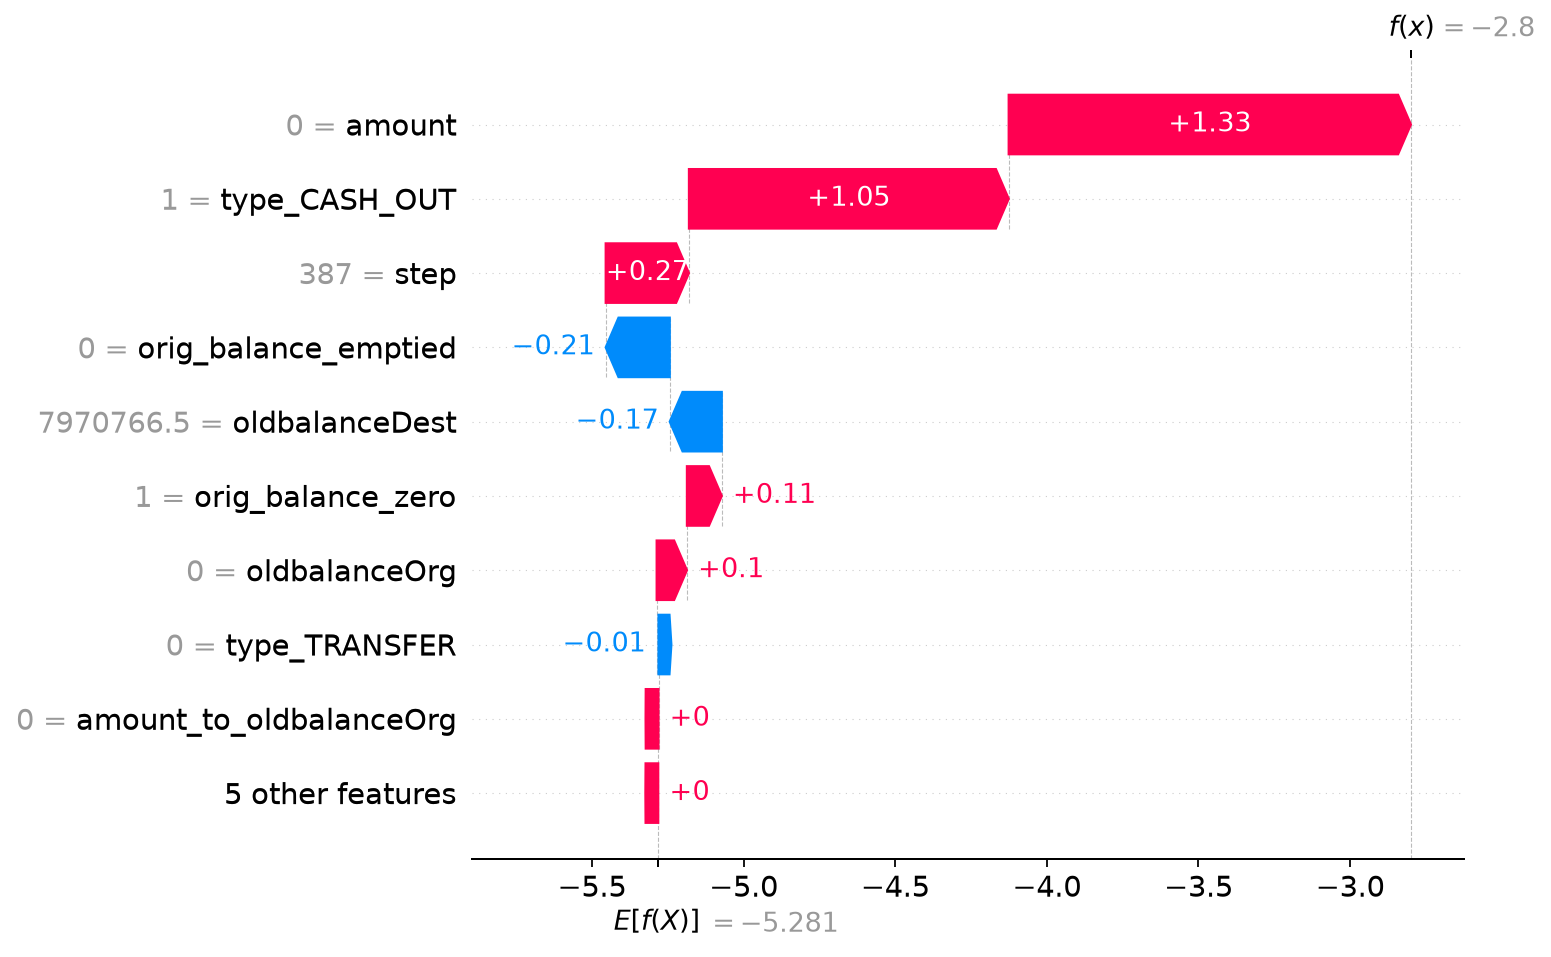

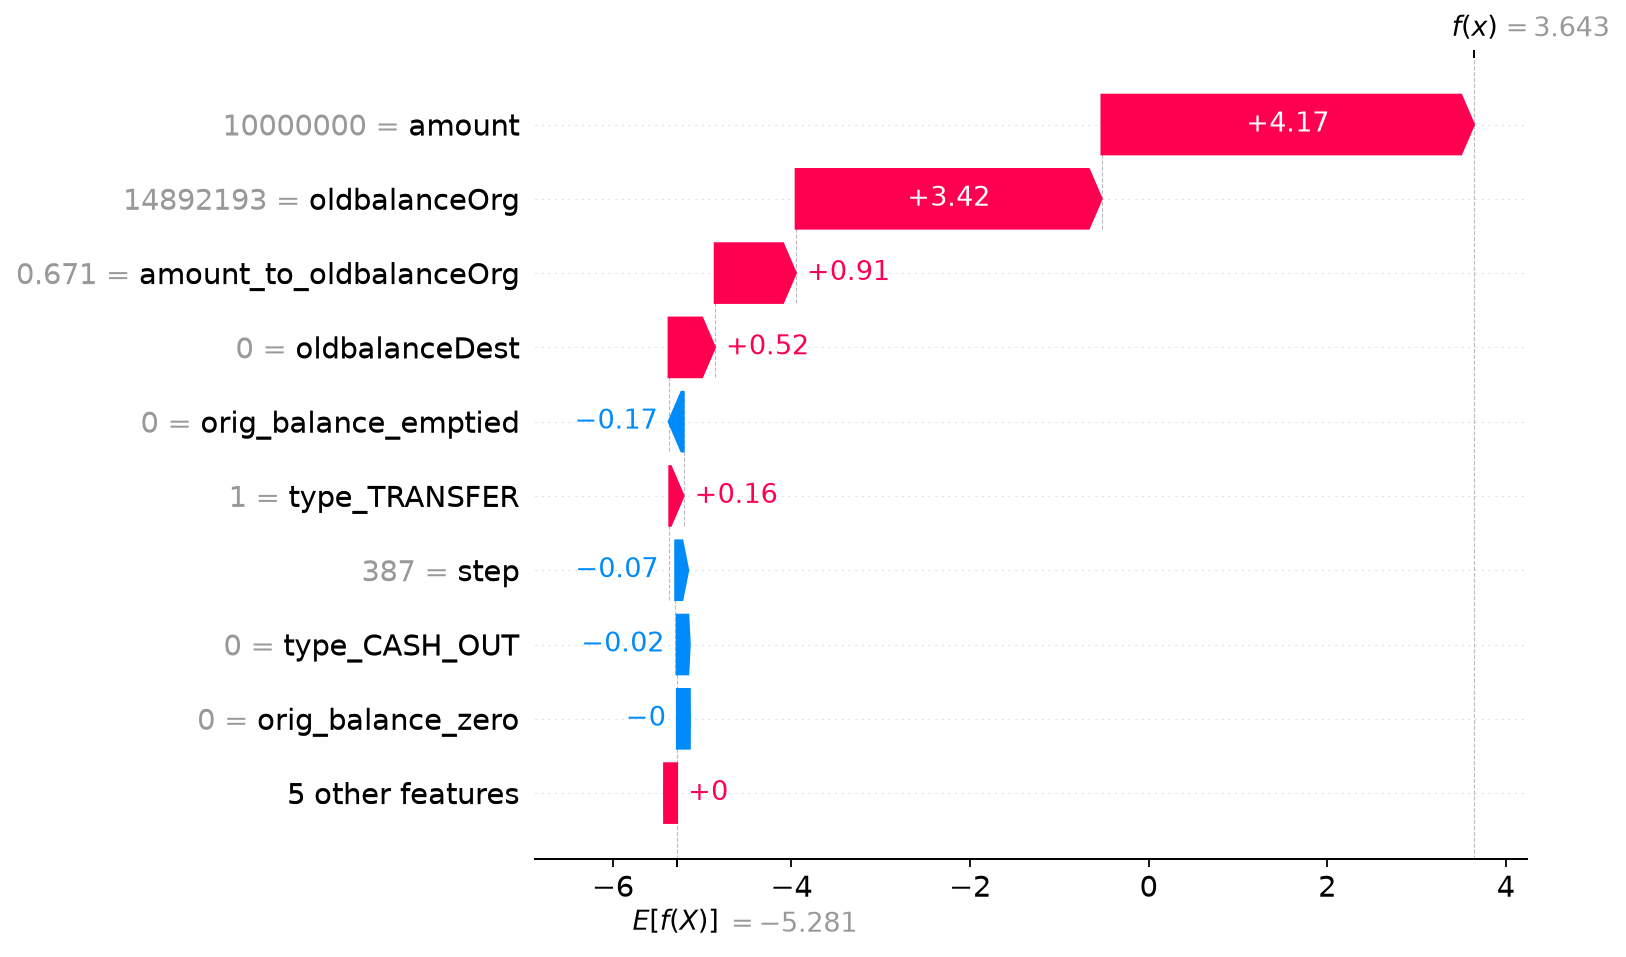

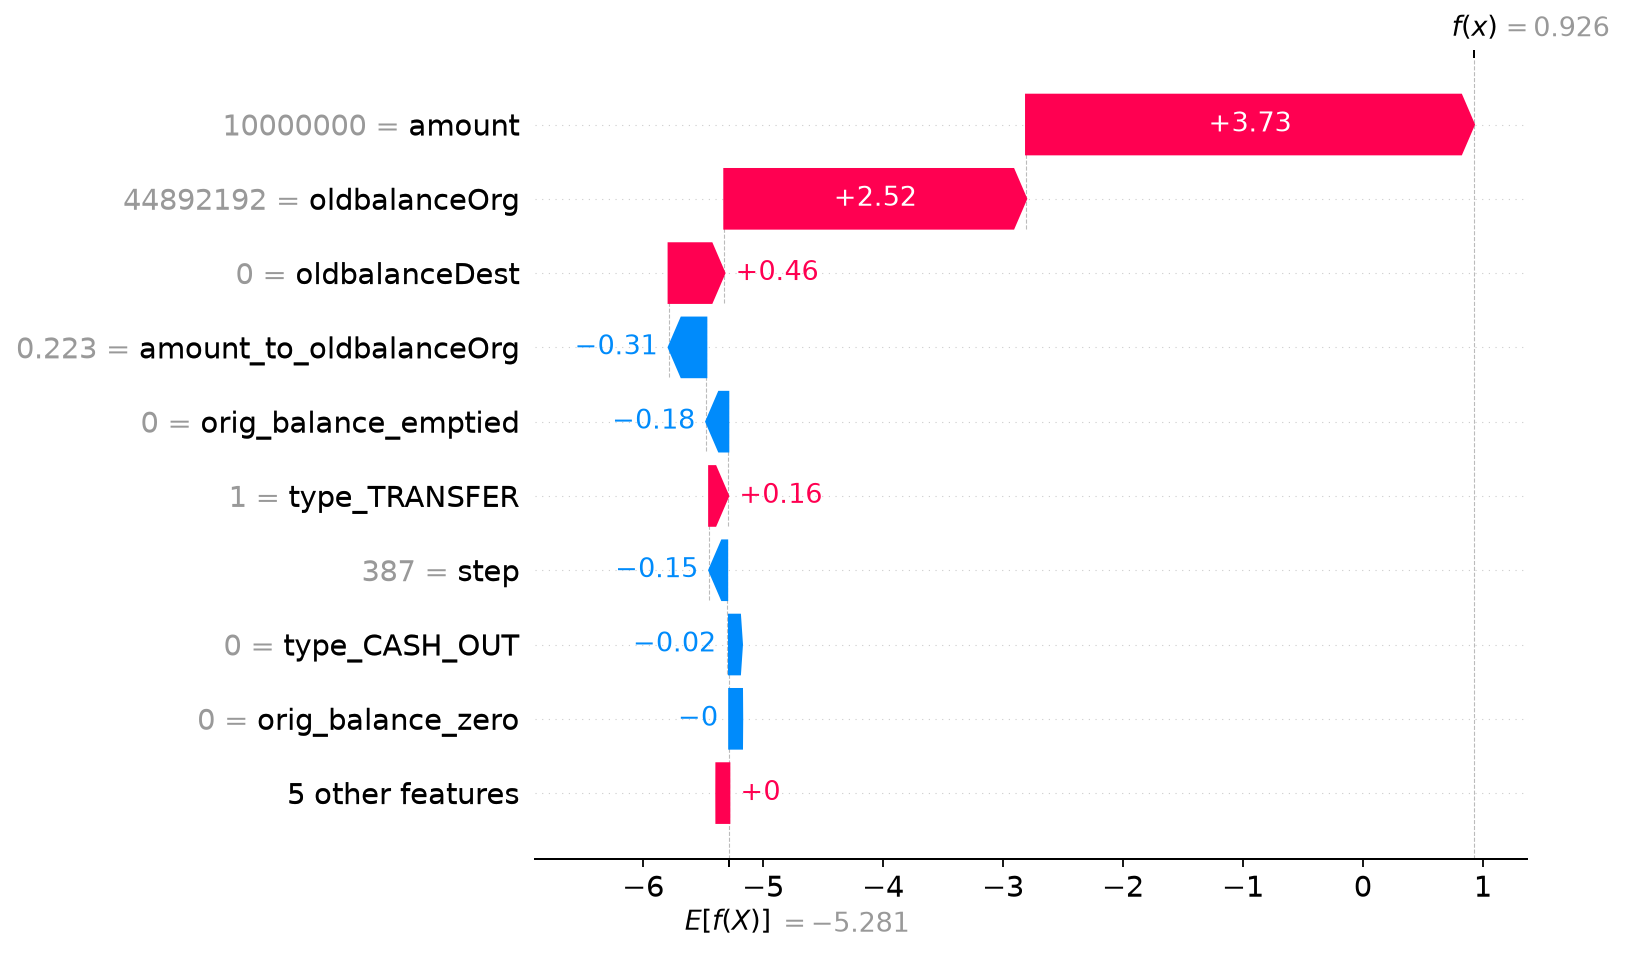

In [4]:
display(r['local_cases'])
display(pd.read_csv(ROOT/'artifacts/local_explanations.csv'))
for path in sorted((ROOT/'reports/figures/interpretability').glob('waterfall_*.png')):
    display(Image(filename=str(path)))

## Interpretación completa y limitaciones

El False Negative tiene monto y saldo origen cero. La base negativa no se compensa con sus contribuciones positivas; ausencia de vaciado y saldo destino añaden contribuciones negativas. El análisis no selecciona nuevo threshold ni cambia el modelo.

In [5]:
display(Markdown((ROOT/'docs/model_interpretability.md').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT/'artifacts/shap_group_comparison.csv'))
display(r['mlflow'])

# Interpretabilidad del modelo XGBoost

## Objetivo modelo y período
Explicar global y localmente el champion provisional XGBoost tuned de Fase 3, sin reentrenar, cambiar features, seleccionar threshold ni leer Production. Solo se abren validation_X.npy y validation_y.npy, correspondientes a steps 321–400: 1,398,242 filas y 868 fraudes. No se abre el CSV raw ni matrices Train. Las métricas recargadas reproducen exactamente Fase 3: AP 0.999918590, TP 867, TN 1,397,374, FN 1, FP 0.

Modelo fuente: `.\data\processed\phase3_models\XGBoost.ubj`; SHA256 `44a20bc0e2abbd276ae94790db404248d2ab2c5d01025b00b2e4f935b6f220e4`; run fuente `1d353308f1e3427094a221667f3da9de`. El archivo tiene 44 rondas, pero sklearn usa best_iteration+1 = 24. Tree SHAP y gain nativo se calculan exclusivamente con esas 24 rondas; no se modifica el archivo ni se explica accidentalmente el ensemble posterior al mejor punto. Features y matrices de Fase 2 permanecen iguales.

## Metodología y muestra
Tree SHAP exacto nativo de XGBoost, pred_contribs=True, approx_contribs=False, iteration_range=(0,24). Se utiliza SHAP para representar Explanation, beeswarm, bar y waterfall. Método tree-path-dependent: las estadísticas de cobertura de entrenamiento ya guardadas en los árboles definen la referencia; no se crea un background nuevo. Las contribuciones y la base se expresan en log-odds. Sigmoid(base + suma SHAP) reconstruye el score. No son puntos de probabilidad aditivos ni probabilidades calibradas.

Muestra de 2,868 filas: todos los 868 fraudes y 2,000 no fraudes, uniformes sin reemplazo, semilla 42. Su prevalencia es 30.26%, frente a 0.062078% real. No debe confundirse esta muestra enriquecida de explicación con la distribución de Validation. La importancia poblacional se estima ponderando las medias por clase con la prevalencia real; es una estimación basada en 2,000 no fraudes, no SHAP exhaustivo de toda Validation. Casos locales extremos se explican por separado y no se añaden a la muestra global.

Errores máximos de reconstrucción: margen 2.62260437e-06; score 2.38418579e-07. Las pruebas también verifican las rondas efectivas y el slicing de matrices memory-mapped.

## Explicación global e importancia nativa
| feature | mean_abs_shap | mean_abs_shap_fraud | mean_abs_shap_nonfraud | mean_abs_shap_prevalence_weighted | mean_signed_shap_fraud | mean_signed_shap_nonfraud | native_gain | native_split_count | shap_sample_rank | shap_population_estimate_rank | native_gain_rank |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| orig_balance_emptied | 2.177891 | 6.625342 | 0.247694 | 0.251653 | 6.618984 | -0.247694 | 44566.402344 | 18.000000 | 1 | 1 | 1 |
| amount_to_oldbalanceOrg | 0.387300 | 1.187255 | 0.040120 | 0.040833 | 1.186534 | -0.029473 | 3890.905762 | 40.000000 | 2 | 5 | 3 |
| amount | 0.162184 | 0.423262 | 0.048875 | 0.049108 | 0.421858 | -0.018133 | 462.143860 | 58.000000 | 3 | 3 | 8 |
| oldbalanceDest | 0.116012 | 0.251112 | 0.057378 | 0.057498 | 0.240388 | 0.024583 | 793.911926 | 40.000000 | 4 | 2 | 6 |
| oldbalanceOrg | 0.113520 | 0.277040 | 0.042554 | 0.042699 | 0.266731 | -0.023301 | 679.849670 | 43.000000 | 5 | 4 | 7 |
| type_TRANSFER | 0.077945 | 0.212207 | 0.019675 | 0.019795 | 0.203464 | -0.007291 | 903.499939 | 8.000000 | 6 | 7 | 4 |
| type_CASH_OUT | 0.058412 | 0.101460 | 0.039729 | 0.039768 | -0.017859 | -0.020846 | 216.788086 | 31.000000 | 7 | 6 | 9 |
| step | 0.007054 | 0.008164 | 0.006572 | 0.006573 | -0.007374 | -0.006451 | 13.220498 | 47.000000 | 8 | 8 | 12 |
| dest_is_merchant | 0.004891 | 0.010293 | 0.002547 | 0.002552 | 0.010293 | -0.002198 | 4036.976562 | 1.000000 | 9 | 11 | 2 |
| type_CASH_IN | 0.004273 | 0.007900 | 0.002698 | 0.002701 | 0.007900 | -0.002301 | 809.769836 | 3.000000 | 10 | 10 | 5 |
| orig_balance_zero | 0.003664 | 0.002085 | 0.004349 | 0.004347 | -0.001820 | 0.001676 | 106.221573 | 9.000000 | 11 | 9 | 10 |
| type_PAYMENT | 0.002326 | 0.002667 | 0.002178 | 0.002178 | 0.002667 | -0.002001 | 65.239990 | 1.000000 | 12 | 12 | 11 |
| type_DEBIT | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 13 | 13 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 13 | 13 | 13 |

La feature dominante es orig_balance_emptied, seguida de amount_to_oldbalanceOrg y amount. En la muestra enriquecida, el vaciado concentra 69.91% de la suma de mean absolute SHAP; esto no representa porcentaje de varianza explicada ni causalidad. La ponderación por prevalencia mantiene vaciado en primer lugar, pero cambia el orden de las demás variables: revisar ambas columnas/rankings.

Gain nativo resume mejora media de la función objetivo en los splits del ensemble efectivo; split count cuenta frecuencia de uso. Mean absolute SHAP resume magnitud de contribuciones sobre una distribución de explicación concreta. Sus rankings pueden diferir por cobertura, ponderación de clases, correlación entre saldo/monto/ratio/vaciado, interacciones y distribución de la muestra. Ambos identifican vaciado como dominante; no implican efectos causales.

## Dirección dependence e interacciones
Beeswarm y tres dependence plots están en reports/figures/interpretability. Monto y ratio muestran relaciones no lineales; no debe imponerse una relación monotónica a todas las transacciones. Las contribuciones del saldo destino tienden a reducirse al aumentar su valor en esta muestra, pero hay contexto e interacciones. Las variables monetarias se presentan como log1p cuando la escala es grande. El color representa ratio o vaciado según el gráfico; es evidencia descriptiva de dependencia, no efecto causal.

| feature | spearman_value_vs_shap |
| --- | --- |
| step | -0.045929 |
| amount | 0.723860 |
| oldbalanceOrg | 0.386254 |
| oldbalanceDest | -0.864863 |
| amount_to_oldbalanceOrg | 0.122317 |
| orig_balance_zero | 0.746878 |
| orig_balance_emptied | 0.791924 |
| dest_is_merchant | -0.747898 |
| type_CASH_IN | -0.631439 |
| type_CASH_OUT | 0.846292 |
| type_DEBIT | nan |
| type_PAYMENT | -0.748434 |
| type_TRANSFER | 0.665540 |
| type_UNKNOWN | nan |

Los coeficientes Spearman son descriptivos de valor versus contribución dentro de la muestra enriquecida; constantes se dejan vacías. En 128 filas elegidas con semilla 42 se calcularon interaction values; el error máximo de sus sumas marginales es 9.53674316e-07. Se reportan componentes simétricos off-diagonal, sin sumar dos veces ambas posiciones ni interpretar causalidad:

| feature_a | feature_b | mean_abs_pair_component |
| --- | --- | --- |
| amount | oldbalanceOrg | 0.169062 |
| amount | orig_balance_emptied | 0.069262 |
| oldbalanceDest | type_TRANSFER | 0.062086 |
| oldbalanceOrg | orig_balance_emptied | 0.058550 |
| amount | amount_to_oldbalanceOrg | 0.053566 |

La interacción de monto y saldo origen destaca, coherente con las features derivadas del mismo par de variables. La muestra de interacción es pequeña y no ofrece conclusiones poblacionales precisas.

## Regla de vaciado
orig_balance_emptied ocupa rank 1 con mean |SHAP| 2.177891. Si vale 1, la contribución media es +6.746533 log-odds y el score medio en la muestra es 0.974467. Si vale 0, la contribución media es -0.247096, con score medio 0.010702. Son medias de subgrupos de una muestra enriquecida; no estiman un efecto de intervención.

El modelo aprende principalmente la regla de vaciado, pero no exclusivamente. Fraudes detectados con vaciado 0 reciben contribuciones fuertes de monto, saldo origen y ratio. Vaciado se definió antes del scoring como saldo origen positivo y abs(monto - saldo previo) <=0.01, calculado en float64 antes del almacenamiento float32.

## Fraudes fuera de la regla
16 de 868 fraudes (1.843318%) tienen vaciado 0. Detectados 15/16 (93.75%) a threshold de referencia 0.5. Scores entre 0.057349406 y 0.974499404. Los 15 correctamente detectados son TRANSFER de monto 10 millones y saldo previo superior al monto. El restante es CASH_OUT con monto y saldo origen cero. Esto es un patrón observado, no una afirmación sobre el mecanismo generador ni una regla causal.

| feature | mean_abs_shap |
| --- | --- |
| amount | 3.861571 |
| oldbalanceOrg | 3.080130 |
| amount_to_oldbalanceOrg | 0.705125 |
| oldbalanceDest | 0.482755 |
| orig_balance_emptied | 0.172451 |

| validation_row_index | step | amount | oldbalanceOrg | amount_to_oldbalanceOrg | score | prediction_05 |
| --- | --- | --- | --- | --- | --- | --- |
| 644394 | 354.000000 | 10000000.000000 | 19299230.000000 | 0.518155 | 0.967110 | 1 |
| 770843 | 357.000000 | 10000000.000000 | 10653152.000000 | 0.938689 | 0.962584 | 1 |
| 790223 | 359.000000 | 10000000.000000 | 12056779.000000 | 0.829409 | 0.962584 | 1 |
| 799030 | 362.000000 | 10000000.000000 | 17677120.000000 | 0.565703 | 0.967110 | 1 |
| 832362 | 370.000000 | 10000000.000000 | 11653144.000000 | 0.858137 | 0.962584 | 1 |
| 1174717 | 386.000000 | 10000000.000000 | 21975272.000000 | 0.455057 | 0.958965 | 1 |
| 1174719 | 386.000000 | 10000000.000000 | 11975272.000000 | 0.835054 | 0.962584 | 1 |
| 1174917 | 387.000000 | 10000000.000000 | 44892192.000000 | 0.222756 | 0.716314 | 1 |
| 1174919 | 387.000000 | 10000000.000000 | 34892192.000000 | 0.286597 | 0.958965 | 1 |
| 1174921 | 387.000000 | 10000000.000000 | 24892194.000000 | 0.401732 | 0.958965 | 1 |
| 1174923 | 387.000000 | 10000000.000000 | 14892193.000000 | 0.671493 | 0.974499 | 1 |
| 1174926 | 387.000000 | 0.000000 | 0.000000 | 0.000000 | 0.057349 | 0 |
| 1174933 | 387.000000 | 10000000.000000 | 29110884.000000 | 0.343514 | 0.958965 | 1 |
| 1174935 | 387.000000 | 10000000.000000 | 19110884.000000 | 0.523262 | 0.967110 | 1 |
| 1335483 | 398.000000 | 10000000.000000 | 25618180.000000 | 0.390348 | 0.958965 | 1 |
| 1335485 | 398.000000 | 10000000.000000 | 15618180.000000 | 0.640279 | 0.974499 | 1 |

## Explicaciones locales
threshold 0.5 = reference threshold, not final production threshold.

Los casos se eligen de forma determinística: TP de máximo score, TN de mínimo score, FN de mínimo score, FP de máximo score si existe, TP sin vaciado de máximo score y observación más próxima a 0.5. Los empates usan el primer índice Validation. Los índices no son IDs de clientes ni números de fila raw. Cada caso muestra todos los valores y contribuciones firmadas; local_explanations.csv conserva su estructura reutilizable.

### A_high_score_TP

Índice Validation cero-based 30299; step 322; label 1; score 0.979055464; predicción @0.5 1.

La transferencia iguala monto y saldo previo. El vaciado aproximado aporta +6.700 log-odds, reforzado por ratio 1 y monto; esto supera el valor base negativo. Explica el score alto, sin demostrar causalidad.

| feature | feature_value | shap_log_odds | absolute_rank |
| --- | --- | --- | --- |
| orig_balance_emptied | 1.000000 | 6.699925 | 1 |
| amount_to_oldbalanceOrg | 1.000000 | 0.834668 | 2 |
| amount | 2533650.000000 | 0.788530 | 3 |
| oldbalanceOrg | 2533650.000000 | 0.376110 | 4 |
| oldbalanceDest | 0.000000 | 0.308940 | 5 |
| type_TRANSFER | 1.000000 | 0.202108 | 6 |
| type_CASH_OUT | 0.000000 | -0.079543 | 7 |
| step | 322.000000 | -0.022306 | 8 |
| dest_is_merchant | 0.000000 | 0.010895 | 9 |
| type_CASH_IN | 0.000000 | 0.006812 | 10 |
| type_PAYMENT | 0.000000 | 0.001213 | 11 |
| orig_balance_zero | 0.000000 | -0.001203 | 12 |
| type_DEBIT | 0.000000 | 0.000000 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 14 |
### B_low_score_TN

Índice Validation cero-based 300; step 321; label 0; score 0.003583667; predicción @0.5 0.

El ratio 1.022 aporta positivamente, pero no basta: ausencia de CASH_OUT, vaciado 0, destino merchant y PAYMENT aportan negativamente. La base negativa y el patrón operativo mantienen el score bajo.

| feature | feature_value | shap_log_odds | absolute_rank |
| --- | --- | --- | --- |
| amount_to_oldbalanceOrg | 1.021692 | 0.727198 | 1 |
| type_CASH_OUT | 0.000000 | -0.423248 | 2 |
| orig_balance_emptied | 0.000000 | -0.247797 | 3 |
| dest_is_merchant | 1.000000 | -0.215375 | 4 |
| type_PAYMENT | 1.000000 | -0.126941 | 5 |
| oldbalanceDest | 0.000000 | 0.066319 | 6 |
| type_TRANSFER | 0.000000 | -0.053699 | 7 |
| oldbalanceOrg | 13962.219727 | -0.043330 | 8 |
| amount | 14265.089844 | -0.026398 | 9 |
| step | 321.000000 | -0.003344 | 10 |
| type_CASH_IN | 0.000000 | 0.002465 | 11 |
| orig_balance_zero | 0.000000 | -0.002191 | 12 |
| type_DEBIT | 0.000000 | 0.000000 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 14 |
### C_false_negative

Índice Validation cero-based 1174926; step 387; label 1; score 0.057349406; predicción @0.5 0.

CASH_OUT con monto 0, saldo origen 0 y ratio 0 (sentinel de división por cero), sin vaciado. La base es -5.281 log-odds. Monto (+1.326) y CASH_OUT (+1.054) elevan el margen, pero no lo suficiente; vaciado 0 (-0.211) y saldo destino (-0.172) lo reducen. El score 0.057349 queda bajo 0.5. El error no se atribuye únicamente a una contribución negativa: faltan las grandes contribuciones positivas de los patrones habituales. Debe revisarse este caso de monto cero y su semántica de simulación.

| feature | feature_value | shap_log_odds | absolute_rank |
| --- | --- | --- | --- |
| amount | 0.000000 | 1.326206 | 1 |
| type_CASH_OUT | 1.000000 | 1.054326 | 2 |
| step | 387.000000 | 0.274508 | 3 |
| orig_balance_emptied | 0.000000 | -0.211178 | 4 |
| oldbalanceDest | 7970766.500000 | -0.171508 | 5 |
| orig_balance_zero | 1.000000 | 0.114849 | 6 |
| oldbalanceOrg | 0.000000 | 0.099787 | 7 |
| type_TRANSFER | 0.000000 | -0.006229 | 8 |
| amount_to_oldbalanceOrg | 0.000000 | 0.000511 | 9 |
| dest_is_merchant | 0.000000 | 0.000254 | 10 |
| type_CASH_IN | 0.000000 | 0.000238 | 11 |
| type_PAYMENT | 0.000000 | 0.000139 | 12 |
| type_DEBIT | 0.000000 | 0.000000 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 14 |
### D_false_positive

No existe False Positive en Validation a threshold 0.5; no se inventa caso ni waterfall.
### E_non_rule_TP

Índice Validation cero-based 1174923; step 387; label 1; score 0.974499404; predicción @0.5 1.

TRANSFER por 10 millones con saldo previo 14.892 millones, ratio 0.67149 y vaciado 0. Monto (+4.170), saldo origen (+3.425) y ratio (+0.906) superan la base negativa y la pequeña penalización por ausencia de vaciado. El modelo también reconoce un patrón multivariable fuera de la regla principal.

| feature | feature_value | shap_log_odds | absolute_rank |
| --- | --- | --- | --- |
| amount | 10000000.000000 | 4.169511 | 1 |
| oldbalanceOrg | 14892193.000000 | 3.424731 | 2 |
| amount_to_oldbalanceOrg | 0.671493 | 0.906230 | 3 |
| oldbalanceDest | 0.000000 | 0.516696 | 4 |
| orig_balance_emptied | 0.000000 | -0.166041 | 5 |
| type_TRANSFER | 1.000000 | 0.157851 | 6 |
| step | 387.000000 | -0.066291 | 7 |
| type_CASH_OUT | 0.000000 | -0.016875 | 8 |
| orig_balance_zero | 0.000000 | -0.001748 | 9 |
| dest_is_merchant | 0.000000 | 0.000271 | 10 |
| type_CASH_IN | 0.000000 | 0.000228 | 11 |
| type_PAYMENT | 0.000000 | 0.000096 | 12 |
| type_DEBIT | 0.000000 | 0.000000 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 14 |
### F_nearest_reference_threshold

Índice Validation cero-based 1174917; step 387; label 1; score 0.716314316; predicción @0.5 1.

El score más cercano a 0.5 es 0.716314, a distancia 0.216314. Es el caso más próximo disponible, pero no una transacción realmente cercana a 0.5; no se inventa un caso ambiguo. Monto y saldo origen elevan el margen, mientras el ratio 0.222756 y vaciado 0 lo reducen.

| feature | feature_value | shap_log_odds | absolute_rank |
| --- | --- | --- | --- |
| amount | 10000000.000000 | 3.732511 | 1 |
| oldbalanceOrg | 44892192.000000 | 2.515368 | 2 |
| oldbalanceDest | 0.000000 | 0.464323 | 3 |
| amount_to_oldbalanceOrg | 0.222756 | -0.312828 | 4 |
| orig_balance_emptied | 0.000000 | -0.183002 | 5 |
| type_TRANSFER | 1.000000 | 0.157851 | 6 |
| step | 387.000000 | -0.148507 | 7 |
| type_CASH_OUT | 0.000000 | -0.016875 | 8 |
| orig_balance_zero | 0.000000 | -0.001748 | 9 |
| dest_is_merchant | 0.000000 | 0.000271 | 10 |
| type_CASH_IN | 0.000000 | 0.000228 | 11 |
| type_PAYMENT | 0.000000 | 0.000096 | 12 |
| type_DEBIT | 0.000000 | 0.000000 | 13 |
| type_UNKNOWN | 0.000000 | 0.000000 | 14 |

## Consistencia y robustez cualitativa
| group | rows | feature | mean_abs_shap | mean_signed_shap |
| --- | --- | --- | --- | --- |
| confident_correct | 2866 | orig_balance_emptied | 2.179274 | 1.831925 |
| confident_correct | 2866 | amount_to_oldbalanceOrg | 0.387461 | 0.338897 |
| confident_correct | 2866 | amount | 0.160532 | 0.113346 |
| fraud | 868 | orig_balance_emptied | 6.625352 | 6.618995 |
| fraud | 868 | amount_to_oldbalanceOrg | 1.187254 | 1.186533 |
| fraud | 868 | amount | 0.423262 | 0.421858 |
| incorrect_or_mid_score | 2 | amount | 2.529359 | 2.529359 |
| incorrect_or_mid_score | 2 | oldbalanceOrg | 1.307578 | 1.307578 |
| incorrect_or_mid_score | 2 | type_CASH_OUT | 0.535601 | 0.518726 |
| non_rule_fraud | 16 | amount | 3.861571 | 3.861571 |
| non_rule_fraud | 16 | oldbalanceOrg | 3.080130 | 3.080130 |
| non_rule_fraud | 16 | amount_to_oldbalanceOrg | 0.705125 | 0.666021 |
| nonfraud | 2000 | orig_balance_emptied | 0.247693 | -0.247693 |
| nonfraud | 2000 | oldbalanceDest | 0.057377 | 0.024583 |
| nonfraud | 2000 | amount | 0.048876 | -0.018133 |

Fraudes fáciles están dominados por vaciado y ratio; no fraudes tienen base baja y contribuciones predominantemente pequeñas. El grupo fuera de regla tiene peso mayor de monto/saldo. El FN combina señales positivas débiles con ausencia de la señal dominante y mantiene margen negativo. Esto es coherencia interna del modelo, no robustez de generalización probada. Los grupos de score <=0.1 o >=0.9 son diagnósticos fijos de explicación, no nuevos thresholds operativos; solo se usa 0.5 para errores comparables.

## Limitaciones y no causalidad
SHAP explica contribuciones del modelo a sus predicciones; SHAP NO demuestra causalidad. Las features correlacionadas/derivadas pueden repartir contribuciones de forma dependiente del método y del modelo. Tree-path-dependent usa estadísticas de cobertura y no una distribución causal ni un background representativo de producción. La base no equivale a prevalencia global y el entrenamiento usó peso positivo 10. Las medias de muestra enriquecida difieren de las poblacionales estimadas. Solo hay 16 fraudes fuera de regla y un FN; no se extrapolan conclusiones a errores futuros. Los resultados casi perfectos reflejan un simulador; balances previos y prefijos requieren confirmación operacional. Validation fue reutilizada para tuning, de modo que no es un test independiente. Float32 puede redondear montos grandes. No se hacen cambios de features, modelo, calibración o threshold como consecuencia de este análisis.

## Reproducción y referencias
Desde la raíz, en PowerShell:
```powershell
$env:UV_CACHE_DIR = Join-Path $PWD '.uv-cache'
uv sync --locked
uv run python -m pytest -q
uv run python scripts/run_interpretability.py
uv run python scripts/build_phase4_report.py
```
El segundo script regenera presentación y evidencia sin repetir SHAP ni crear un nuevo run. El primero crea un solo run de interpretabilidad por ejecución, manteniendo los históricos.

[SHAP TreeExplainer y semántica raw/path-dependent](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), [XGBoost contribution prediction y iteration_range](https://xgboost.readthedocs.io/en/stable/prediction.html).


,group,rows,feature,mean_abs_shap,mean_signed_shap
0,fraud,868,step,0.008164,-0.007374
1,fraud,868,amount,0.423262,0.421858
2,fraud,868,oldbalanceOrg,0.277040,0.266731
3,fraud,868,oldbalanceDest,0.251112,0.240388
4,fraud,868,amount_to_oldbalanceOrg,1.187254,1.186533
5,fraud,868,orig_balance_zero,0.002085,-0.001820
6,fraud,868,orig_balance_emptied,6.625352,6.618995
7,fraud,868,dest_is_merchant,0.010293,0.010293
8,fraud,868,type_CASH_IN,0.007900,0.007900
9,fraud,868,type_CASH_OUT,0.101460,-0.017859


{'run_id': '4823399689d0480eac371aa8de02016b', 'experiment_id': '1', 'tracking_uri': 'sqlite:///./mlruns/mlflow.db', 'phase3_history_hashes': {'7fa24d6ea79f4b6d8f62a07236a351f9': '453ccd888c5cc457b7124a8ae45d5e6238cfd540ba64414618802b310ec9c3b6', '33845df18b4a48288e116b0027e6b946': '09a40d866fb9cfbce053f292aed8bf7b89b622107c10c8d41505bbd85f294f89', 'ac0682a9e54a4f75a3b63cd052a1fdc6': '3ab569a3165c503ee90cdd02017172d93ad01e67491b3585b8b75f8e62bf9a6c', 'e5b6ee1abaca488095f18010663e5166': 'a907fd98739d8429e8d026ae4d1f0368e514806e82b1730f56198987e4344959', 'd18fbdce26b74ebf97073b110eca54c2': '8d2f6dd48340297dc42609e20880dffe97dbc937ab74202ca6f8293db84b27bc', 'c59c39c3a2c94ac09c84ab4910a6971b': 'd4af3dc155bc6221ae8e8104cfe2a38cdaf72b009867f02ec5d76b41972c7fd9', 'e2ed011b3ba047e7bded7d278c8b0115': '762b8bdb9458cfe7c0be43156ec86b601715cc2a0760ec02027aee94533b280e', 'ec2c94b13a2f4c8b9d28731222d400a7': '65988ac2af5fc123a45bb258733b6a49e6c345146db18e411b4145651d533802', 'dfeb3a494f8d46a184212798

## Conclusión

Predominio de la regla del simulador y detección multivariable de 15/16 fraudes fuera de regla. Disponibilidad operacional, validación independiente y caso de monto cero requieren revisión. La lógica está en src/fraud_detection/interpretability.py. Este notebook carga artifacts: no reentrena ni lee Production. Detener aquí; Fase 5 requiere autorización.